In [ ]:
# ==============================================================
# Chronic Kidney Disease (CKD) Prediction using Machine Learning
# Notebook : 01_Data_Preprocessing
# Author   : Shoriful Islam
# Purpose  : Dataset Inspection & Data Preprocessing
# ==============================================================

print("="*65)
print(" Chronic Kidney Disease Prediction")
print(" Notebook 01 : Data Preprocessing")
print("="*65)

 Chronic Kidney Disease Prediction
 Notebook 01 : Data Preprocessing


In [ ]:
# ==============================================================
# Import Required Libraries
# ==============================================================

import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries Imported Successfully.")

Libraries Imported Successfully.


In [ ]:
# ==============================================================
# Mount Google Drive
# ==============================================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==============================================================
# Define Project Paths
# ==============================================================

PROJECT_PATH = "/content/drive/MyDrive/CKD Research Project"

DATASET_PATH = os.path.join(PROJECT_PATH, "Dataset")
FIGURE_PATH = os.path.join(PROJECT_PATH, "Figures")
RESULT_PATH = os.path.join(PROJECT_PATH, "Results")
MODEL_PATH = os.path.join(PROJECT_PATH, "Saved_Model")
PAPER_PATH = os.path.join(PROJECT_PATH, "Paper")

print("Project Path Loaded Successfully.\n")

print("Dataset Folder :", DATASET_PATH)
print("Figure Folder  :", FIGURE_PATH)
print("Result Folder  :", RESULT_PATH)
print("Model Folder   :", MODEL_PATH)
print("Paper Folder   :", PAPER_PATH)

Project Path Loaded Successfully.

Dataset Folder : /content/drive/MyDrive/CKD Research Project/Dataset
Figure Folder  : /content/drive/MyDrive/CKD Research Project/Figures
Result Folder  : /content/drive/MyDrive/CKD Research Project/Results
Model Folder   : /content/drive/MyDrive/CKD Research Project/Saved_Model
Paper Folder   : /content/drive/MyDrive/CKD Research Project/Paper


In [ ]:
# ==============================================================
# Load Original Dataset
# ==============================================================

dataset_file = os.path.join(DATASET_PATH, "ckd.csv")

df = pd.read_csv(dataset_file)

print("Dataset Loaded Successfully.\n")

print(f"Dataset Shape : {df.shape}")

Dataset Loaded Successfully.

Dataset Shape : (400, 25)


In [ ]:
# ==============================================================
# Clean Column Names
# ==============================================================

df.columns = (
    df.columns
    .str.replace("'", "", regex=False)
    .str.strip()
    .str.lower()
)

print("Column Names Cleaned Successfully.\n")

print(df.columns.tolist())

Column Names Cleaned Successfully.

['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


In [ ]:
# ==============================================================
# Dataset Overview
# ==============================================================

print(f"Number of Rows    : {df.shape[0]}")
print(f"Number of Columns : {df.shape[1]}")

print("\nFirst Five Records:\n")

display(df.head())

Number of Rows    : 400
Number of Columns : 25

First Five Records:



,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.00,80.00,1.02,1.00,0.00,NaN,normal,notpresent,notpresent,121.00,36.00,1.20,NaN,NaN,15.40,44.00,7800.00,5.20,yes,yes,no,good,no,no,ckd
1,7.00,50.00,1.02,4.00,0.00,NaN,normal,notpresent,notpresent,NaN,18.00,0.80,NaN,NaN,11.30,38.00,6000.00,NaN,no,no,no,good,no,no,ckd
2,62.00,80.00,1.01,2.00,3.00,normal,normal,notpresent,notpresent,423.00,53.00,1.80,NaN,NaN,9.60,31.00,7500.00,NaN,no,yes,no,poor,no,yes,ckd
3,48.00,70.00,1.00,4.00,0.00,normal,abnormal,present,notpresent,117.00,56.00,3.80,111.00,2.50,11.20,32.00,6700.00,3.90,yes,no,no,poor,yes,yes,ckd
4,51.00,80.00,1.01,2.00,0.00,normal,normal,notpresent,notpresent,106.00,26.00,1.40,NaN,NaN,11.60,35.00,7300.00,4.60,no,no,no,good,no,no,ckd


In [ ]:
# ==============================================================
# Data Quality Assessment
# ==============================================================

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\n1. Dataset Shape")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\n" + "=" * 70)

print("2. Data Types")

display(df.dtypes.to_frame(name="Data Type"))

print("\n" + "=" * 70)

print("3. Missing Values")

missing_values = df.isnull().sum()

display(missing_values[missing_values > 0].to_frame(name="Missing Count"))

print("\n" + "=" * 70)

print("4. Duplicate Records")

duplicates = df.duplicated().sum()

print(f"Duplicate Rows : {duplicates}")

print("\n" + "=" * 70)

print("5. Memory Usage")

memory = df.memory_usage(deep=True).sum() / 1024

print(f"Memory Usage : {memory:.2f} KB")

DATASET INFORMATION

1. Dataset Shape
Rows    : 400
Columns : 25

2. Data Types


,Data Type
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,object
pc,object
pcc,object
ba,object
bgr,float64



3. Missing Values


,Missing Count
age,9
bp,12
sg,47
al,46
su,49
rbc,152
pc,65
pcc,4
ba,4
bgr,44



4. Duplicate Records
Duplicate Rows : 0

5. Memory Usage
Memory Usage : 269.23 KB


In [ ]:
# ==============================================================
# Exploratory Dataset Inspection
# ==============================================================

print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print("\nFirst 5 Records")
display(df.head())

print("\nLast 5 Records")
display(df.tail())

print("\nRandom 5 Records")
display(df.sample(5, random_state=42))

print("\n" + "=" * 70)

print("NUMERICAL FEATURES")

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Total Numerical Features : {len(numerical_columns)}")

print(numerical_columns)

print("\n" + "=" * 70)

print("CATEGORICAL FEATURES")

categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

print(f"Total Categorical Features : {len(categorical_columns)}")

print(categorical_columns)

print("\n" + "=" * 70)

print("STATISTICAL SUMMARY")

display(df.describe().T)

print("\n" + "=" * 70)

print("CATEGORICAL SUMMARY")

display(df.describe(include='object').T)

DATASET OVERVIEW

First 5 Records


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.00,80.00,1.02,1.00,0.00,NaN,normal,notpresent,notpresent,121.00,36.00,1.20,NaN,NaN,15.40,44.00,7800.00,5.20,yes,yes,no,good,no,no,ckd
1,7.00,50.00,1.02,4.00,0.00,NaN,normal,notpresent,notpresent,NaN,18.00,0.80,NaN,NaN,11.30,38.00,6000.00,NaN,no,no,no,good,no,no,ckd
2,62.00,80.00,1.01,2.00,3.00,normal,normal,notpresent,notpresent,423.00,53.00,1.80,NaN,NaN,9.60,31.00,7500.00,NaN,no,yes,no,poor,no,yes,ckd
3,48.00,70.00,1.00,4.00,0.00,normal,abnormal,present,notpresent,117.00,56.00,3.80,111.00,2.50,11.20,32.00,6700.00,3.90,yes,no,no,poor,yes,yes,ckd
4,51.00,80.00,1.01,2.00,0.00,normal,normal,notpresent,notpresent,106.00,26.00,1.40,NaN,NaN,11.60,35.00,7300.00,4.60,no,no,no,good,no,no,ckd



Last 5 Records


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
395,55.00,80.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,140.00,49.00,0.50,150.00,4.90,15.70,47.00,6700.00,4.90,no,no,no,good,no,no,notckd
396,42.00,70.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,75.00,31.00,1.20,141.00,3.50,16.50,54.00,7800.00,6.20,no,no,no,good,no,no,notckd
397,12.00,80.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,100.00,26.00,0.60,137.00,4.40,15.80,49.00,6600.00,5.40,no,no,no,good,no,no,notckd
398,17.00,60.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,114.00,50.00,1.00,135.00,4.90,14.20,51.00,7200.00,5.90,no,no,no,good,no,no,notckd
399,58.00,80.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,131.00,18.00,1.10,141.00,3.50,15.80,53.00,6800.00,6.10,no,no,no,good,no,no,notckd



Random 5 Records


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
209,19.00,70.00,1.02,0.00,0.00,NaN,normal,notpresent,notpresent,NaN,NaN,NaN,NaN,NaN,11.50,NaN,6900.00,NaN,no,no,no,good,no,no,ckd
280,47.00,80.00,NaN,NaN,NaN,NaN,NaN,notpresent,notpresent,93.00,33.00,0.90,144.00,4.50,13.30,52.00,8100.00,5.20,no,no,no,good,no,no,notckd
33,60.00,100.00,1.02,2.00,0.00,abnormal,abnormal,notpresent,notpresent,140.00,55.00,2.50,NaN,NaN,10.10,29.00,NaN,NaN,yes,no,no,poor,no,no,ckd
210,59.00,100.00,1.01,4.00,2.00,normal,normal,notpresent,notpresent,255.00,132.00,12.80,135.00,5.70,7.30,20.00,9800.00,3.90,yes,yes,yes,good,no,yes,ckd
93,73.00,100.00,1.01,3.00,2.00,abnormal,abnormal,present,notpresent,295.00,90.00,5.60,140.00,2.90,9.20,30.00,7000.00,3.20,yes,yes,yes,poor,no,no,ckd



NUMERICAL FEATURES
Total Numerical Features : 14
['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']

CATEGORICAL FEATURES
Total Categorical Features : 11
['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']

STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
age,391.00,51.48,17.17,2.00,42.00,55.00,64.50,90.00
bp,388.00,76.47,13.68,50.00,70.00,80.00,80.00,180.00
sg,353.00,1.02,0.01,1.00,1.01,1.02,1.02,1.02
al,354.00,1.02,1.35,0.00,0.00,0.00,2.00,5.00
su,351.00,0.45,1.10,0.00,0.00,0.00,0.00,5.00
bgr,356.00,148.04,79.28,22.00,99.00,121.00,163.00,490.00
bu,381.00,57.43,50.50,1.50,27.00,42.00,66.00,391.00
sc,383.00,3.07,5.74,0.40,0.90,1.30,2.80,76.00
sod,313.00,137.53,10.41,4.50,135.00,138.00,142.00,163.00
pot,312.00,4.63,3.19,2.50,3.80,4.40,4.90,47.00



CATEGORICAL SUMMARY


,count,unique,top,freq
rbc,248,2,normal,201
pc,335,2,normal,259
pcc,396,2,notpresent,354
ba,396,2,notpresent,374
htn,398,2,no,251
dm,397,2,no,260
cad,398,2,no,364
appet,399,3,good,316
pe,399,3,no,322
ane,399,2,no,339


In [ ]:
# ==============================================================
# Missing Value Analysis
# ==============================================================

print("=" * 80)
print("MISSING VALUE ANALYSIS")
print("=" * 80)

# Missing count
missing_count = df.isnull().sum()

# Missing percentage
missing_percentage = (missing_count / len(df)) * 100

# Create summary table
missing_df = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Keep only columns with missing values
missing_df = missing_df[missing_df["Missing Values"] > 0]

# Sort
missing_df = missing_df.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(missing_df)

missing_df.to_csv(
    os.path.join(RESULT_PATH, "01_Missing_Value_Summary.csv"),
    index=True
)
print("\n")

print(f"Total Features with Missing Values : {missing_df.shape[0]}")

MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage (%)
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75




Total Features with Missing Values : 24


Figure 01 saved successfully!


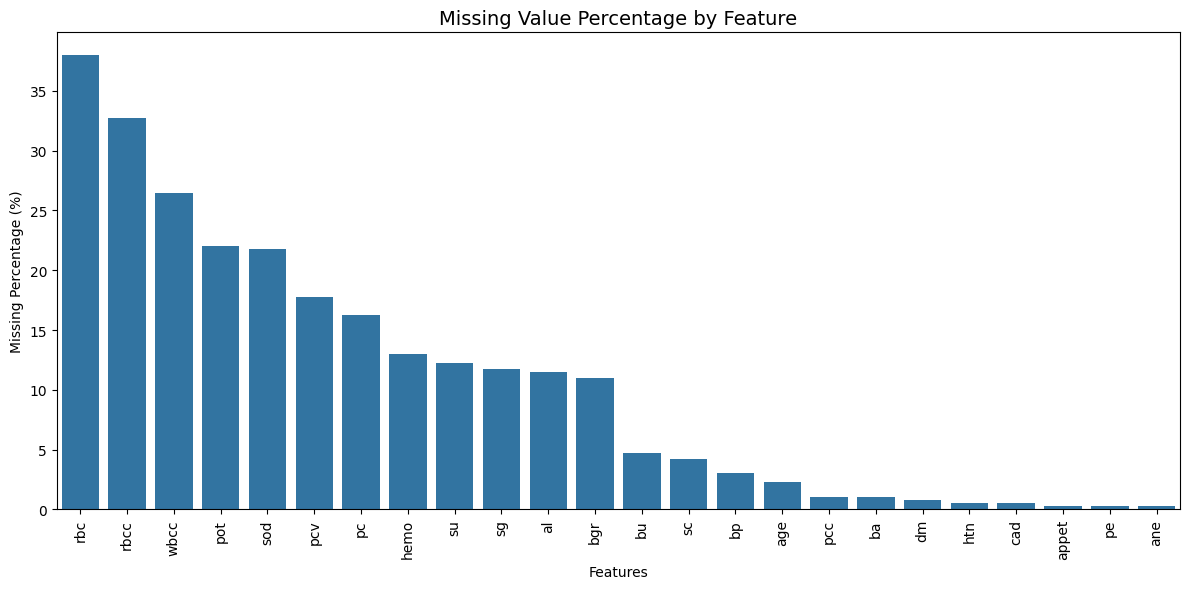

In [ ]:
# ==============================================================
# Missing Value Visualization
# ==============================================================

plt.figure(figsize=(12,6))

sns.barplot(
    x=missing_df.index,
    y=missing_df["Missing Percentage (%)"]
)

plt.title("Missing Value Percentage by Feature", fontsize=14)
plt.xlabel("Features")
plt.ylabel("Missing Percentage (%)")

plt.xticks(rotation=90)

plt.tight_layout()
# ==============================================================
# Save Figure 01: Missing Value Distribution
# ==============================================================

plt.savefig(
    os.path.join(FIGURE_PATH, "01_Missing_Value_Distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

print("Figure 01 saved successfully!")

plt.show()

In [ ]:
# ==============================================================
# Unique Values in Each Categorical Feature
# ==============================================================

print("=" * 80)
print("UNIQUE VALUES OF CATEGORICAL FEATURES")
print("=" * 80)

for column in categorical_columns:

    print(f"\nFeature : {column}")
    print("-"*60)

    print(df[column].unique())

    print("="*80)

UNIQUE VALUES OF CATEGORICAL FEATURES

Feature : rbc
------------------------------------------------------------
[nan 'normal' 'abnormal']

Feature : pc
------------------------------------------------------------
['normal' 'abnormal' nan]

Feature : pcc
------------------------------------------------------------
['notpresent' 'present' nan]

Feature : ba
------------------------------------------------------------
['notpresent' 'present' nan]

Feature : htn
------------------------------------------------------------
['yes' 'no' nan]

Feature : dm
------------------------------------------------------------
['yes' 'no' nan]

Feature : cad
------------------------------------------------------------
['no' 'yes' nan]

Feature : appet
------------------------------------------------------------
['good' 'poor' nan 'no']

Feature : pe
------------------------------------------------------------
['no' 'yes' nan 'good']

Feature : ane
-------------------------------------------------------

In [ ]:
# ==============================================================
# Detect Invalid Categorical Values
# ==============================================================

print("=" * 80)
print("INVALID VALUE DETECTION")
print("=" * 80)

print("\nInvalid values in 'appet'")
display(df[df["appet"] == "no"])

print("\nInvalid values in 'pe'")
display(df[df["pe"] == "good"])

print("\nInvalid values in 'class'")
display(df[df["class"] == "no"])

INVALID VALUE DETECTION

Invalid values in 'appet'


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
369,75.00,70.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,107.00,48.00,0.80,144.00,3.50,13.60,46.00,10300.00,4.80,no,NaN,no,no,good,no,no



Invalid values in 'pe'


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
369,75.00,70.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,107.00,48.00,0.80,144.00,3.50,13.60,46.00,10300.00,4.80,no,NaN,no,no,good,no,no



Invalid values in 'class'


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
369,75.00,70.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,107.00,48.00,0.80,144.00,3.50,13.60,46.00,10300.00,4.80,no,NaN,no,no,good,no,no


In [ ]:
# ==============================================================
# Dataset Integrity Check
# ==============================================================

print("=" * 80)
print("DATASET INTEGRITY CHECK")
print("=" * 80)

# Display rows around the suspicious record
display(df.loc[365:372])

DATASET INTEGRITY CHECK


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
365,24.00,80.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,93.00,46.00,1.00,145.00,3.50,NaN,NaN,10700.00,6.30,no,no,no,good,no,no,notckd
366,60.00,80.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,81.00,15.00,0.50,141.00,3.60,15.00,46.00,10500.00,5.30,no,no,no,good,no,no,notckd
367,68.00,60.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,125.00,41.00,1.10,139.00,3.80,17.40,50.00,6700.00,6.10,no,no,no,good,no,no,notckd
368,30.00,80.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,82.00,42.00,0.70,146.00,5.00,14.90,45.00,9400.00,5.90,no,no,no,good,no,no,notckd
369,75.00,70.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,107.00,48.00,0.80,144.00,3.50,13.60,46.00,10300.00,4.80,no,NaN,no,no,good,no,no
370,69.00,70.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,83.00,42.00,1.20,139.00,3.70,16.20,50.00,9300.00,5.40,no,no,no,good,no,no,notckd
371,28.00,60.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,79.00,50.00,0.50,145.00,5.00,17.60,51.00,6500.00,5.00,no,no,no,good,no,no,notckd
372,72.00,60.00,1.02,0.00,0.00,normal,normal,notpresent,notpresent,109.00,26.00,0.90,150.00,4.90,15.00,52.00,10500.00,5.50,no,no,no,good,no,no,notckd


In [ ]:
# ==============================================================
# Remove Corrupted Record
# ==============================================================

print("=" * 80)
print("REMOVE CORRUPTED RECORD")
print("=" * 80)

# Dataset shape before removing
print(f"Shape before removing: {df.shape}")

# Remove the corrupted row (index = 369)
df = df.drop(index=369).reset_index(drop=True)

# Dataset shape after removing
print(f"Shape after removing: {df.shape}")

print("\nCorrupted record removed successfully.")

REMOVE CORRUPTED RECORD
Shape before removing: (400, 25)
Shape after removing: (399, 25)

Corrupted record removed successfully.


In [ ]:
# ==============================================================
# Data Type Validation
# ==============================================================

print("=" * 80)
print("DATA TYPE VALIDATION")
print("=" * 80)

# Display data types
display(df.dtypes)

# Numerical Features
numerical_columns = df.select_dtypes(include=['number']).columns.tolist()

# Categorical Features
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

print("\nNumerical Features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical Features:", len(categorical_columns))
print(categorical_columns)

DATA TYPE VALIDATION


,0
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,object
pc,object
pcc,object
ba,object
bgr,float64



Numerical Features: 14
['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']

Categorical Features: 11
['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


In [ ]:
# ==============================================================
# Skewness Analysis
# ==============================================================

print("=" * 80)
print("SKEWNESS ANALYSIS")
print("=" * 80)

skew_df = pd.DataFrame({
    "Skewness": df[numerical_columns].skew()
})

display(skew_df.sort_values(by="Skewness", ascending=False))

SKEWNESS ANALYSIS


,Skewness
pot,11.57
sc,7.50
bu,2.63
su,2.46
bgr,2.01
wbcc,1.63
bp,1.60
al,0.99
sg,-0.17
rbcc,-0.18


In [ ]:
# ==============================================================
# Missing Value Imputation
# ==============================================================

print("=" * 80)
print("MISSING VALUE IMPUTATION")
print("=" * 80)

# ---------- Mean Imputation ----------
mean_columns = ['sg', 'hemo', 'pcv', 'rbcc']

for col in mean_columns:
    df[col] = df[col].fillna(df[col].mean())

# ---------- Median Imputation ----------
median_columns = [
    'age', 'bp', 'al', 'su', 'bgr',
    'bu', 'sc', 'sod', 'pot', 'wbcc'
]

for col in median_columns:
    df[col] = df[col].fillna(df[col].median())

# ---------- Mode Imputation ----------
mode_columns = [
    'rbc', 'pc', 'pcc', 'ba',
    'htn', 'dm', 'cad',
    'appet', 'pe', 'ane'
]

for col in mode_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after imputation:\n")
display(df.isnull().sum())

MISSING VALUE IMPUTATION

Missing values after imputation:



,0
age,0
bp,0
sg,0
al,0
su,0
rbc,0
pc,0
pcc,0
ba,0
bgr,0


In [ ]:
print("=" * 80)
print("VERIFY MISSING VALUES")
print("=" * 80)

total_missing = df.isnull().sum().sum()

print(f"Total Missing Values Remaining: {total_missing}")

VERIFY MISSING VALUES
Total Missing Values Remaining: 0


In [ ]:
# ==============================================================
# Final Category Verification
# ==============================================================

print("=" * 80)
print("FINAL CATEGORY VERIFICATION")
print("=" * 80)

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

FINAL CATEGORY VERIFICATION

rbc
rbc
normal      352
abnormal     47
Name: count, dtype: int64

pc
pc
normal      323
abnormal     76
Name: count, dtype: int64

pcc
pcc
notpresent    357
present        42
Name: count, dtype: int64

ba
ba
notpresent    377
present        22
Name: count, dtype: int64

htn
htn
no     252
yes    147
Name: count, dtype: int64

dm
dm
no     262
yes    137
Name: count, dtype: int64

cad
cad
no     365
yes     34
Name: count, dtype: int64

appet
appet
good    317
poor     82
Name: count, dtype: int64

pe
pe
no     323
yes     76
Name: count, dtype: int64

ane
ane
no     339
yes     60
Name: count, dtype: int64

class
class
ckd       250
notckd    149
Name: count, dtype: int64


In [ ]:
# ==============================================================
# Label Encoding
# ==============================================================

from sklearn.preprocessing import LabelEncoder

print("=" * 80)
print("LABEL ENCODING")
print("=" * 80)

label_encoders = {}

for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"\n{col}")
    print(mapping)

LABEL ENCODING

rbc
{'abnormal': np.int64(0), 'normal': np.int64(1)}

pc
{'abnormal': np.int64(0), 'normal': np.int64(1)}

pcc
{'notpresent': np.int64(0), 'present': np.int64(1)}

ba
{'notpresent': np.int64(0), 'present': np.int64(1)}

htn
{'no': np.int64(0), 'yes': np.int64(1)}

dm
{'no': np.int64(0), 'yes': np.int64(1)}

cad
{'no': np.int64(0), 'yes': np.int64(1)}

appet
{'good': np.int64(0), 'poor': np.int64(1)}

pe
{'no': np.int64(0), 'yes': np.int64(1)}

ane
{'no': np.int64(0), 'yes': np.int64(1)}

class
{'ckd': np.int64(0), 'notckd': np.int64(1)}


In [ ]:
# ==============================================================
# Dataset Information After Encoding
# ==============================================================

print("=" * 80)
print("DATASET INFORMATION")
print("=" * 80)

display(df.head())

print("\nDataset Shape:", df.shape)

print("\nData Types")
display(df.dtypes)

DATASET INFORMATION


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.00,80.00,1.02,1.00,0.00,1,1,0,0,121.00,36.00,1.20,138.00,4.40,15.40,44.00,7800.00,5.20,1,1,0,0,0,0,0
1,7.00,50.00,1.02,4.00,0.00,1,1,0,0,121.00,18.00,0.80,138.00,4.40,11.30,38.00,6000.00,4.71,0,0,0,0,0,0,0
2,62.00,80.00,1.01,2.00,3.00,1,1,0,0,423.00,53.00,1.80,138.00,4.40,9.60,31.00,7500.00,4.71,0,1,0,1,0,1,0
3,48.00,70.00,1.00,4.00,0.00,1,0,1,0,117.00,56.00,3.80,111.00,2.50,11.20,32.00,6700.00,3.90,1,0,0,1,1,1,0
4,51.00,80.00,1.01,2.00,0.00,1,1,0,0,106.00,26.00,1.40,138.00,4.40,11.60,35.00,7300.00,4.60,0,0,0,0,0,0,0



Dataset Shape: (399, 25)

Data Types


,0
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,int64
pc,int64
pcc,int64
ba,int64
bgr,float64


In [ ]:
# ==============================================================
# Save Clean Dataset
# ==============================================================

import os

output_path = os.path.join(DATASET_PATH, "clean_ckd.csv")

df.to_csv(output_path, index=False)

print(f"Clean dataset saved successfully!")

print(output_path)

Clean dataset saved successfully!
/content/drive/MyDrive/CKD Research Project/Dataset/clean_ckd.csv
